In [2]:
!pip install ultralytics transformers torch torchvision pillow -q

In [3]:
import torch
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from ultralytics import YOLOWorld
from transformers import CLIPModel, CLIPProcessor

# --- ۱. بارگذاری YOLO-World (بدون نیاز به آموزش) ---
yolo_model = YOLOWorld('yolov8s-worldv2.pt')
yolo_classes = ["cheetah", "wild boar", "urial sheep", "wolf", "fox", "animal"]
yolo_model.set_classes(yolo_classes)

# --- ۲. بارگذاری CLIP برای تأیید برچسب نهایی ---
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

animal_labels_en = [
    "a photo of a cheetah",
    "a photo of a wild boar",
    "a photo of a urial (wild sheep)",
    "a photo of a wolf",
    "a photo of a fox",
    "a photo of an unknown animal or background"
]
animal_labels_fa = ["یوزپلنگ", "گراز", "قوچ", "گرگ", "روباه", "نامشخص"]

device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model.to(device)
print(f"✅ مدل‌ها آماده‌اند. دستگاه: {device}")


# --- ۳. تابع اصلی: تشخیص + طبقه‌بندی + رسم کادر ---
def detect_and_classify(image_path, conf_threshold=0.25):
    """تصویر ورودی را تشخیص و طبقه‌بندی می‌کند و تصویر خروجی را ذخیره می‌کند."""
    image = Image.open(image_path).convert("RGB")
    original = image.copy()

    # اجرای YOLO-World
    results = yolo_model(image, conf=conf_threshold)
    boxes = results[0].boxes

    if boxes is None or len(boxes) == 0:
        print("⚠️ هیچ حیوانی در تصویر پیدا نشد.")
        display(original)
        return None, original

    draw = ImageDraw.Draw(image)
    report_lines = []

    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        yolo_conf = float(box.conf[0])
        yolo_label = yolo_classes[int(box.cls[0])]

        # برش ناحیه و اجرای CLIP
        cropped = image.crop((x1, y1, x2, y2))
        inputs = clip_processor(
            text=animal_labels_en,
            images=cropped,
            return_tensors="pt",
            padding=True
        ).to(device)

        with torch.no_grad():
            outputs = clip_model(**inputs)
            probs = outputs.logits_per_image.softmax(dim=1)[0]

        best_idx = int(probs.argmax())
        best_label_fa = animal_labels_fa[best_idx]
        clip_conf = float(probs[best_idx])

        # رسم کادر و برچسب
        color = (0, 200, 0) if clip_conf > 0.5 else (255, 140, 0)
        draw.rectangle([x1, y1, x2, y2], outline=color, width=4)

        # نوشتن متن (بدون فونت خاص، چون ممکن است در Colab موجود نباشد)
        text = f"{best_label_fa} {clip_conf:.0%}"
        draw.text((x1 + 5, max(y1 - 12, 0)), text, fill=color)

        report_lines.append(
            f"  کادر {i+1}: YOLO='{yolo_label}' ({yolo_conf:.0%}) "
            f"→ CLIP='{best_label_fa}' ({clip_conf:.0%})"
        )

    # ذخیره تصویر خروجی
    output_path = "result_" + image_path
    image.save(output_path)

    # نمایش نتایج
    print("📋 گزارش تشخیص:")
    print("\n".join(report_lines))
    print(f"\n💾 تصویر خروجی ذخیره شد: {output_path}\n")
    display(image)

    return output_path, image

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 18 packages in 805ms
Prepared 2 packages in 4.67s
Installed 2 packages in 6ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 6.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 171MiB/s]


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (5 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

✅ مدل‌ها آماده‌اند. دستگاه: cpu


👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 17.jpg to 17.jpg

🖼️ در حال پردازش: 17.jpg
--------------------------------------------------

0: 448x640 1 wolf, 461.7ms
Speed: 4.7ms preprocess, 461.7ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='wolf' (39%) → CLIP='گرگ' (98%)

💾 تصویر خروجی ذخیره شد: result_17.jpg



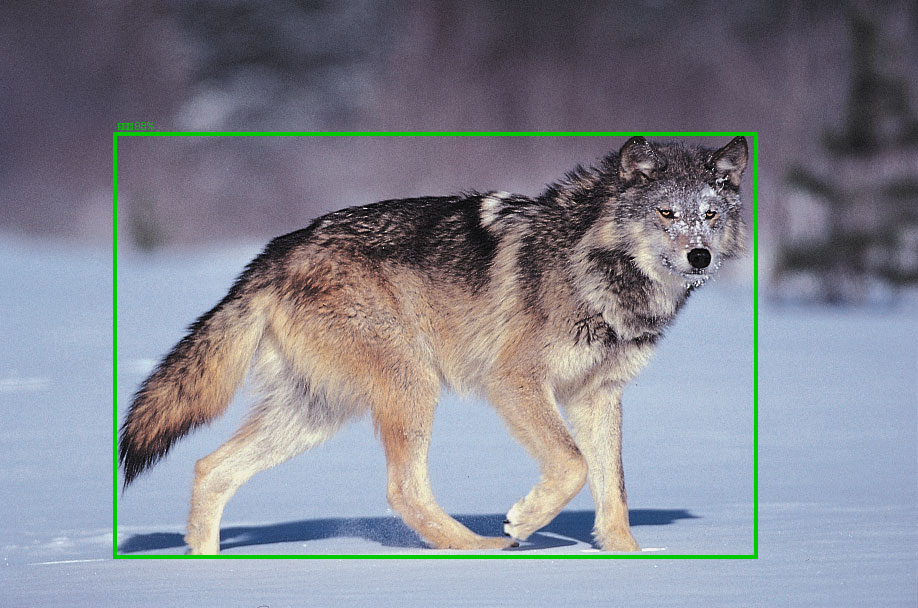

In [14]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 15.jpg to 15 (2).jpg

🖼️ در حال پردازش: 15 (2).jpg
--------------------------------------------------

0: 416x640 1 wolf, 426.3ms
Speed: 5.5ms preprocess, 426.3ms inference, 1.3ms postprocess per image at shape (1, 3, 416, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='wolf' (51%) → CLIP='روباه' (43%)

💾 تصویر خروجی ذخیره شد: result_15 (2).jpg



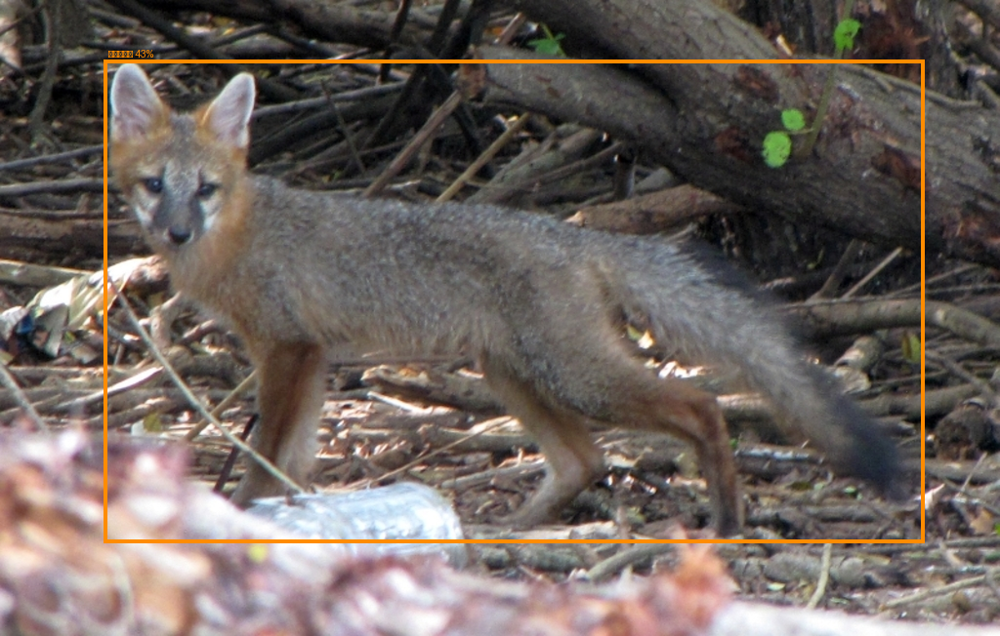

In [15]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 14.jpg to 14 (1).jpg

🖼️ در حال پردازش: 14 (1).jpg
--------------------------------------------------

0: 640x640 1 wolf, 641.8ms
Speed: 6.7ms preprocess, 641.8ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='wolf' (37%) → CLIP='روباه' (57%)

💾 تصویر خروجی ذخیره شد: result_14 (1).jpg



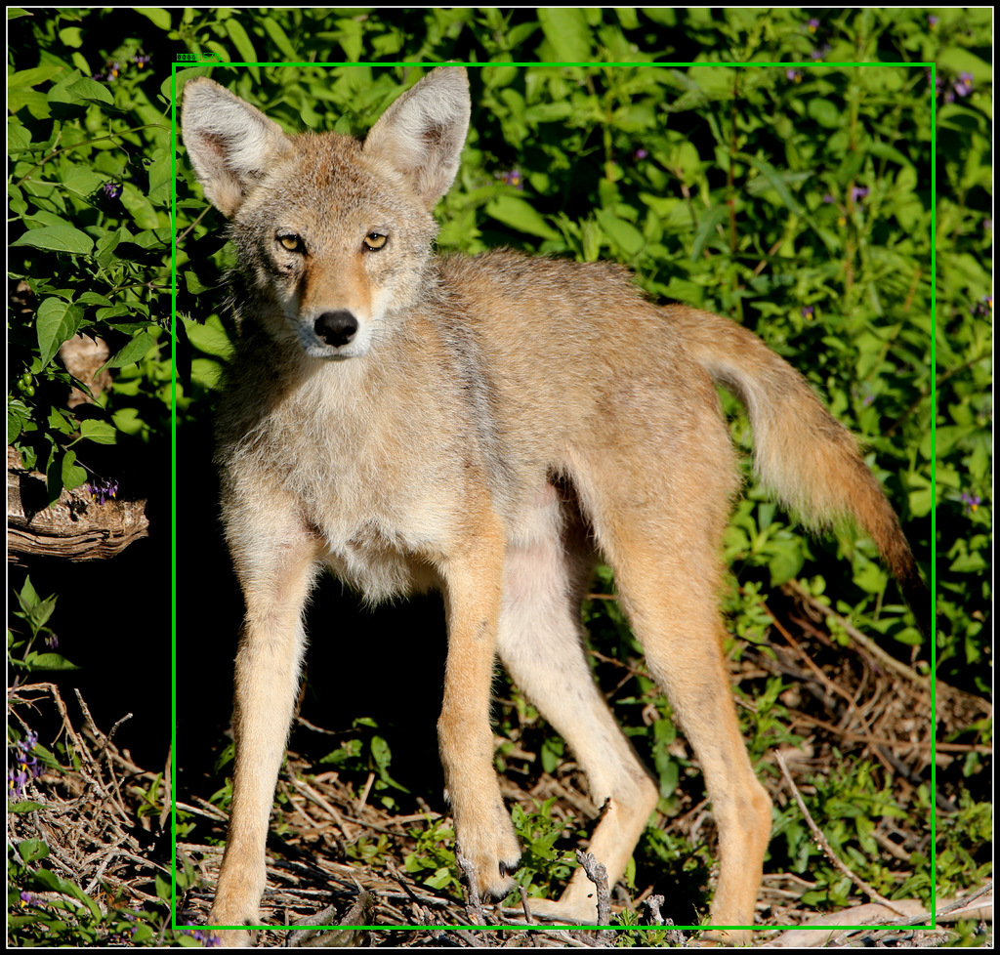

In [16]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 10.jpg to 10 (2).jpg

🖼️ در حال پردازش: 10 (2).jpg
--------------------------------------------------

0: 640x640 2 urial sheeps, 649.3ms
Speed: 5.5ms preprocess, 649.3ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='urial sheep' (64%) → CLIP='یوزپلنگ' (100%)
  کادر 2: YOLO='urial sheep' (30%) → CLIP='نامشخص' (41%)

💾 تصویر خروجی ذخیره شد: result_10 (2).jpg



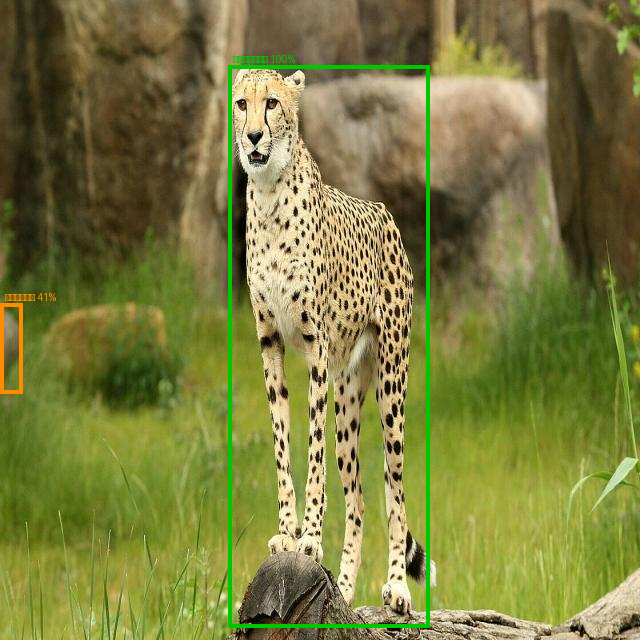

In [17]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 9.jpg to 9.jpg

🖼️ در حال پردازش: 9.jpg
--------------------------------------------------

0: 640x640 1 urial sheep, 660.0ms
Speed: 5.7ms preprocess, 660.0ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='urial sheep' (57%) → CLIP='یوزپلنگ' (99%)

💾 تصویر خروجی ذخیره شد: result_9.jpg



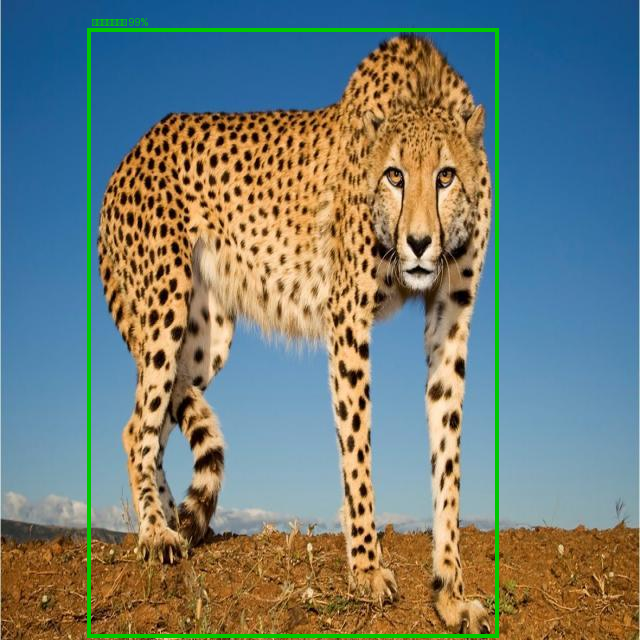

In [18]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 8.jpg to 8.jpg

🖼️ در حال پردازش: 8.jpg
--------------------------------------------------

0: 640x640 1 animal, 649.9ms
Speed: 5.3ms preprocess, 649.9ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='animal' (25%) → CLIP='یوزپلنگ' (100%)

💾 تصویر خروجی ذخیره شد: result_8.jpg



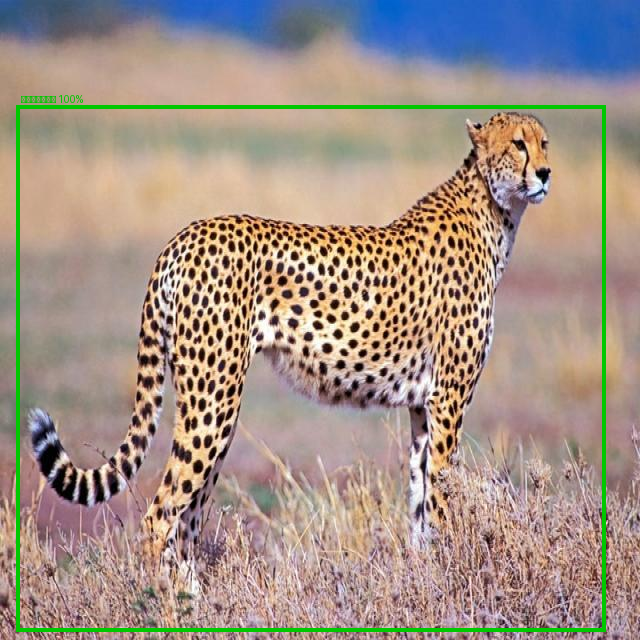

In [19]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 7.jpg to 7.jpg

🖼️ در حال پردازش: 7.jpg
--------------------------------------------------

0: 640x640 1 cheetah, 644.0ms
Speed: 5.3ms preprocess, 644.0ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='cheetah' (45%) → CLIP='یوزپلنگ' (100%)

💾 تصویر خروجی ذخیره شد: result_7.jpg



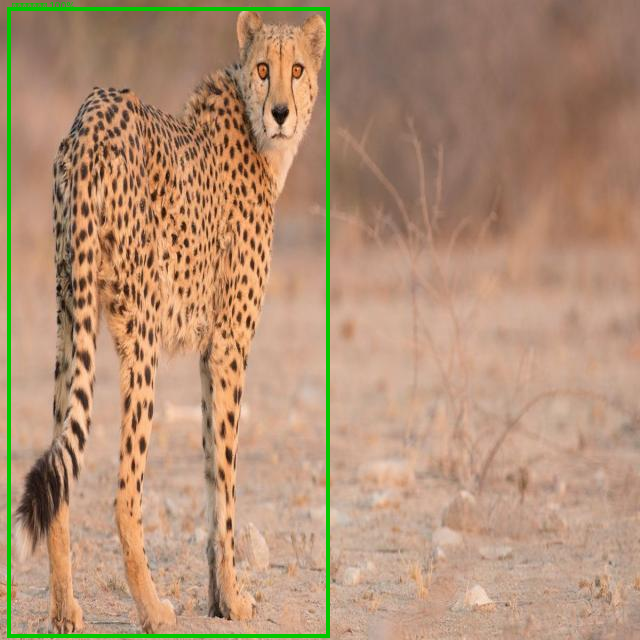

In [20]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 6.jpg to 6.jpg

🖼️ در حال پردازش: 6.jpg
--------------------------------------------------

0: 640x640 1 cheetah, 666.4ms
Speed: 5.3ms preprocess, 666.4ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='cheetah' (58%) → CLIP='یوزپلنگ' (100%)

💾 تصویر خروجی ذخیره شد: result_6.jpg



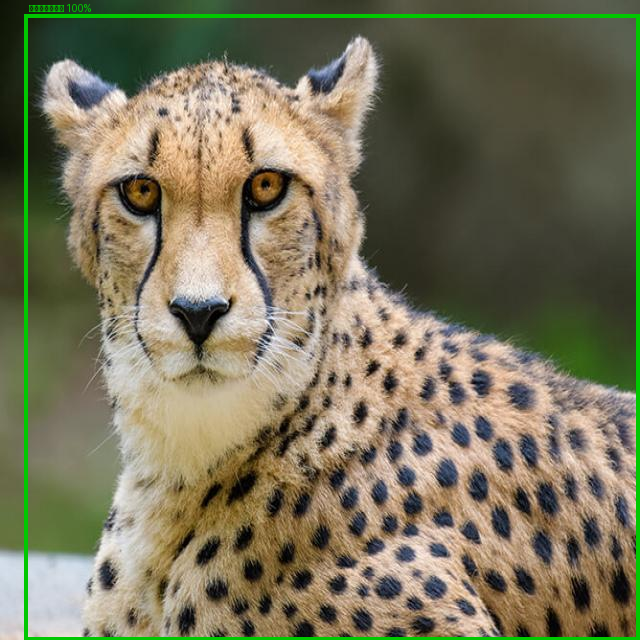

In [21]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 5.jpg to 5.jpg

🖼️ در حال پردازش: 5.jpg
--------------------------------------------------

0: 640x640 1 urial sheep, 631.1ms
Speed: 5.7ms preprocess, 631.1ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='urial sheep' (43%) → CLIP='یوزپلنگ' (98%)

💾 تصویر خروجی ذخیره شد: result_5.jpg



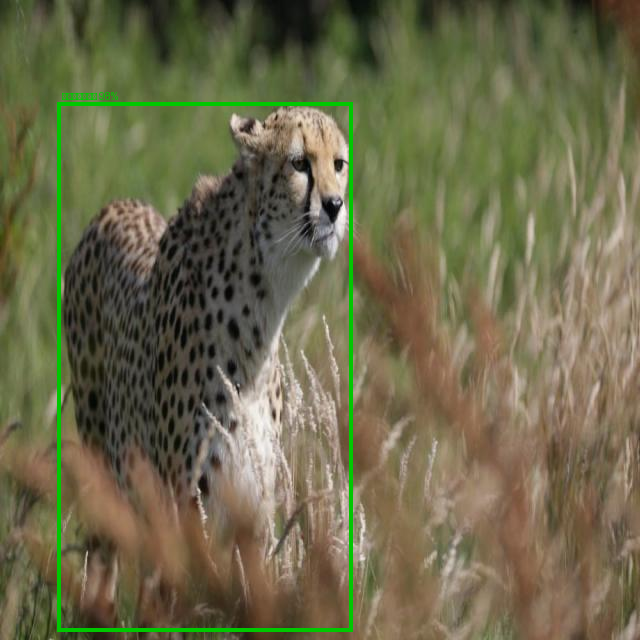

In [22]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 4.jpg to 4.jpg

🖼️ در حال پردازش: 4.jpg
--------------------------------------------------

0: 640x640 1 cheetah, 664.7ms
Speed: 5.4ms preprocess, 664.7ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='cheetah' (74%) → CLIP='یوزپلنگ' (100%)

💾 تصویر خروجی ذخیره شد: result_4.jpg



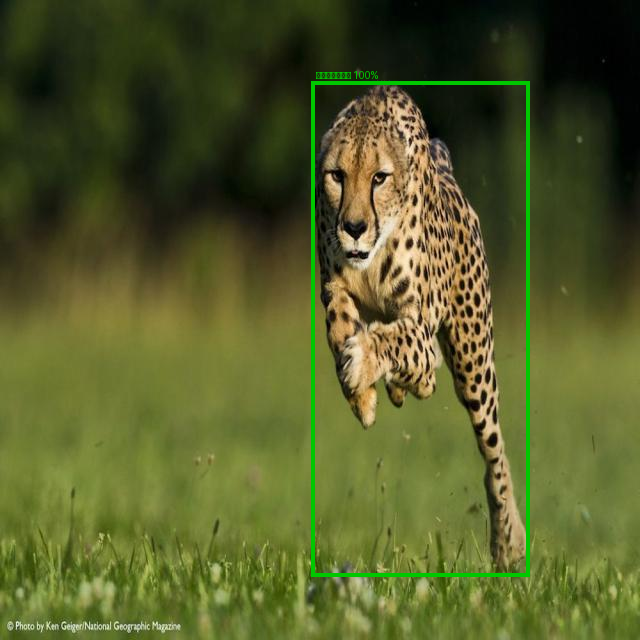

In [23]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 18.jpg to 18.jpg

🖼️ در حال پردازش: 18.jpg
--------------------------------------------------

0: 640x640 1 wild boar, 641.4ms
Speed: 6.6ms preprocess, 641.4ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='wild boar' (36%) → CLIP='گراز' (100%)

💾 تصویر خروجی ذخیره شد: result_18.jpg



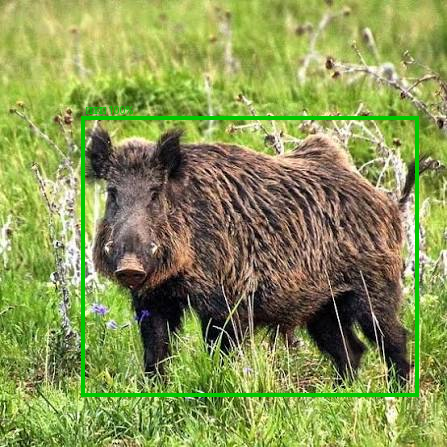

In [27]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 19.jpeg to 19.jpeg

🖼️ در حال پردازش: 19.jpeg
--------------------------------------------------

0: 544x640 2 urial sheeps, 567.8ms
Speed: 5.6ms preprocess, 567.8ms inference, 4.2ms postprocess per image at shape (1, 3, 544, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='urial sheep' (93%) → CLIP='گراز' (100%)
  کادر 2: YOLO='urial sheep' (88%) → CLIP='گراز' (78%)

💾 تصویر خروجی ذخیره شد: result_19.jpeg



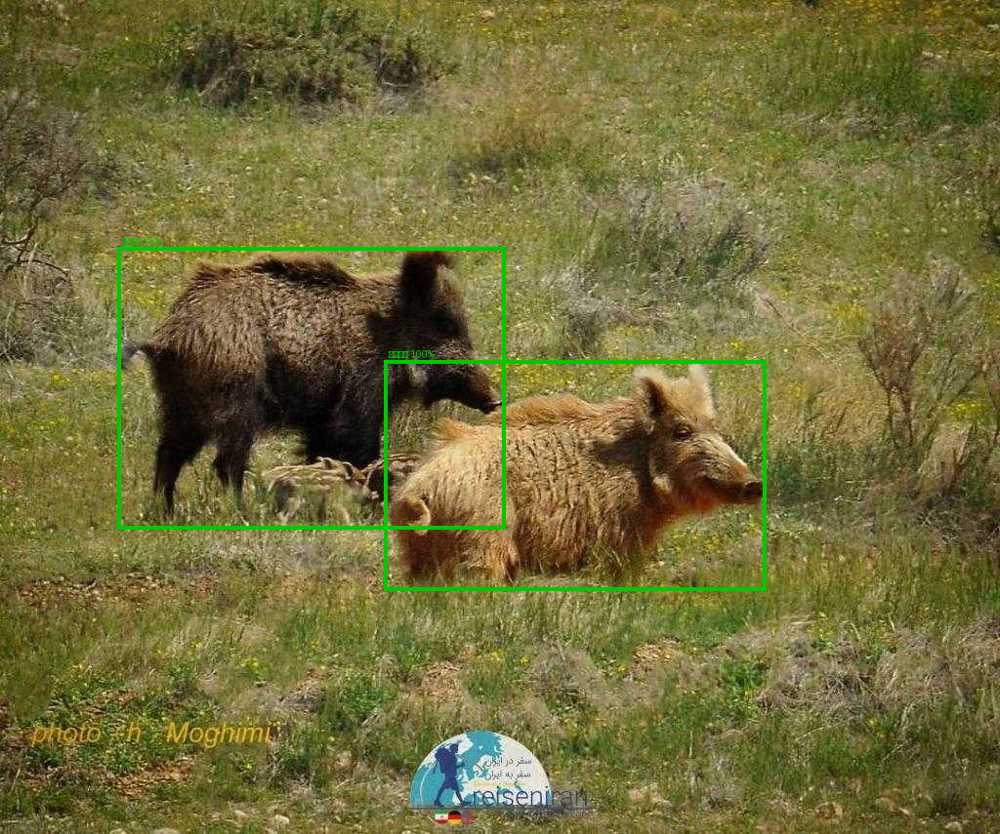

In [28]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:


Saving 20.jpg to 20.jpg

🖼️ در حال پردازش: 20.jpg
--------------------------------------------------

0: 448x640 1 urial sheep, 454.9ms
Speed: 5.9ms preprocess, 454.9ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)
📋 گزارش تشخیص:
  کادر 1: YOLO='urial sheep' (66%) → CLIP='قوچ' (76%)

💾 تصویر خروجی ذخیره شد: result_20.jpg



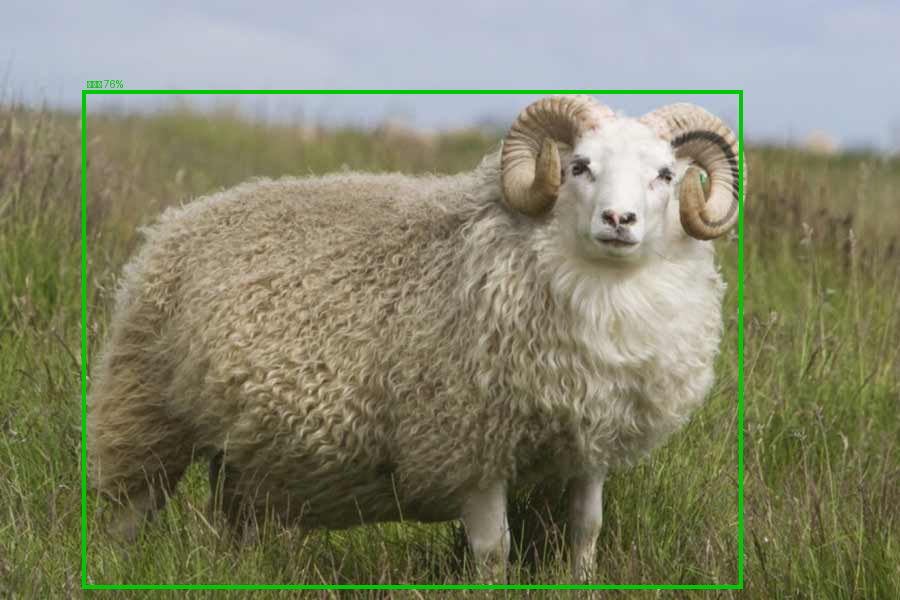

In [29]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)

In [ ]:
from google.colab import files

print("👇 روی دکمه زیر کلیک کنید و عکس مورد نظر خود را از دستگاه انتخاب کنید:")
uploaded = files.upload()

# پردازش همه فایل‌های آپلود شده
for filename in uploaded.keys():
    print(f"\n🖼️ در حال پردازش: {filename}")
    print("-" * 50)
    result_path, result_img = detect_and_classify(filename)
    print("=" * 50)